<a href="https://colab.research.google.com/github/NikitaBeker/titanic-survival-project/blob/main/notebooks/stage3_part1_eda.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

100%|██████████| 4.76M/4.76M [00:00<00:00, 91.6MB/s]

Extracting files...


Размер очищенного датасета: (100000, 31)
Размер выборки (25%): (25000, 31)
Размер оставшейся части (75%): (75000, 31)


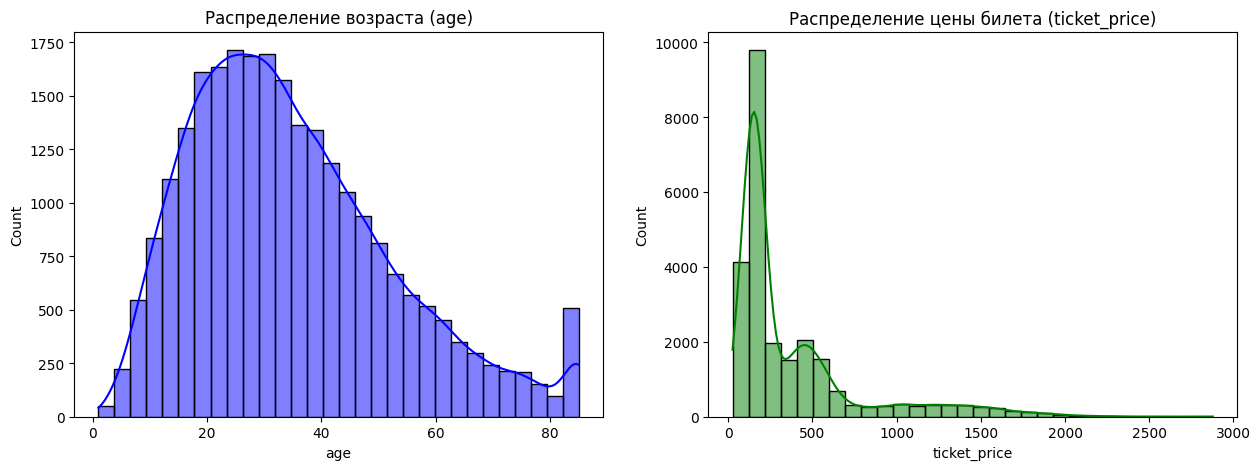

Статистика по выборке (25%):
Age - Среднее: 34.82, Медиана: 31.90
Ticket Price - Среднее: 374.97, Медиана: 194.58


In [1]:
import kagglehub
import os
import glob
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

path = kagglehub.dataset_download("mobeenfatimah/titanic-dataset")
csv_files = glob.glob(os.path.join(path, "*.csv"))
df = pd.read_csv(csv_files[0])

num_cols = df.select_dtypes(include=[np.number]).columns
cat_cols = df.select_dtypes(include=['object', 'category']).columns
for col in num_cols:
    df[col] = df[col].fillna(df[col].median())
for col in cat_cols:
    df[col] = df[col].fillna(df[col].mode()[0])
df = df.drop_duplicates().reset_index(drop=True)

# Удаление логических ошибок
df = df[(df['age'] > 0) & (df['age'] <= 100)]
df = df[df['ticket_price'] > 0]

print(f"Размер очищенного датасета: {df.shape}")

# 2. 25% датасета для анализа
sample_df = df.sample(frac=0.25, random_state=42)
rest_df = df.drop(sample_df.index) # Оставшиеся 75% для проверки гипотез
print(f"Размер выборки (25%): {sample_df.shape}")
print(f"Размер оставшейся части (75%): {rest_df.shape}")

# 3. Графики и статистика для двух признаков (age и ticket_price)
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
sns.histplot(sample_df['age'], bins=30, kde=True, ax=axes[0], color='blue')
axes[0].set_title('Распределение возраста (age)')
sns.histplot(sample_df['ticket_price'], bins=30, kde=True, ax=axes[1], color='green')
axes[1].set_title('Распределение цены билета (ticket_price)')
plt.show()

print("Статистика по выборке (25%):")
print(f"Age - Среднее: {sample_df['age'].mean():.2f}, Медиана: {sample_df['age'].median():.2f}")
print(f"Ticket Price - Среднее: {sample_df['ticket_price'].mean():.2f}, Медиана: {sample_df['ticket_price'].median():.2f}")

In [3]:
# Проверка гипотез на оставшейся части (rest_df)

# Гипотеза 1: Женщины выживали чаще мужчин. (Мысли: при эвакуации женщин пропускали первыми).
survival_by_gender = rest_df.groupby('gender')['survived'].mean()
print("Выживаемость по полу:\n", survival_by_gender)
# Тест:
print("Женщины:", survival_by_gender.get('Female', 0), "Мужчины:", survival_by_gender.get('Male', 0))

# Гипотеза 2: Пассажиры 1 класса выживали чаще, чем 3 класса. (Мысли: у них был ближе доступ к шлюпкам).
survival_by_class = rest_df.groupby('class')['survived'].mean()
print("\nВыживаемость по классу:\n", survival_by_class)

# Гипотеза 3: Доступ к шлюпкам (lifeboat_access) напрямую влияет на выживание. (Мысли: если доступ > 0.5, шансы выше).
high_access = rest_df[rest_df['lifeboat_access'] > 0.5]['survived'].mean()
low_access = rest_df[rest_df['lifeboat_access'] <= 0.5]['survived'].mean()
print(f"\nВыживаемость при доступе > 0.5: {high_access:.2%}, при <= 0.5: {low_access:.2%}")

Выживаемость по полу:
 gender
Female        0.379432
Male          0.200708
Non-Binary    0.203540
Name: survived, dtype: float64
Женщины: 0.37943213103812673 Мужчины: 0.20070797402320878

Выживаемость по классу:
 class
1    0.491918
2    0.338259
3    0.213639
Name: survived, dtype: float64

Выживаемость при доступе > 0.5: 39.75%, при <= 0.5: 21.80%
